# Deep RL navigation of a pneumatic soft robot in the brain ventricles (SOFA + PPO)

**Goal.** Train a policy that steers a two-section pneumatic soft continuum robot from a
Kocher's-point entry through the frontal horn of the lateral ventricle to a target 80 mm
along a planned path, without leaving the lumen, using physics simulation (SOFA) and
Proximal Policy Optimization (PPO).

**What this notebook contains**

1. Environment and reproducibility
2. Data: patient geometry, planned path, Kocher entry
3. The decision problem (MDP): observation, action, reward, termination
4. Simulator and training system
5. Training (re-runnable with SOFA; logs included)
6. Results: learning curves, evaluation, trajectories, reward-shaping ablation (v1 vs v2)
7. Discussion, limitations, next steps

All figures and tables below are computed from the files in `results/` (training logs and
recorded SOFA rollouts), so the notebook runs without SOFA. Cells that call SOFA are
guarded by `RUN_SOFA = False`; see `ENVIRONMENT.md` for the full build.

## 1. Environment and reproducibility

In [1]:
import csv, glob, json, os, platform, sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

RUN_SOFA = False          # True: re-run training / rollouts (needs the SOFA build, ENVIRONMENT.md)
RES = 'results'
FIG = 'figures'
os.makedirs(FIG, exist_ok=True)

# colours: categorical slots 1-2 of the reference palette; reference path in dark ink
V1, V2, BASE, INK, MUTED, WALL = '#2a78d6', '#eb6834', '#8a8a86', '#0b0b0b', '#52514e', '#c9c8c3'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 9, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e5e0',
                     'grid.linewidth': 0.6, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'lines.linewidth': 2})
print('python', platform.python_version(), '| numpy', np.__version__, '| matplotlib', matplotlib.__version__)
print('Reported runs used: SOFA v26.06 (a4d4962a), Python 3.12.13, torch 2.7.1+cpu, '
      'stable-baselines3 2.6.0, gymnasium 1.1.1, Ubuntu 24.04, 6 CPU cores')

python 3.13.13 | numpy 2.5.5 | matplotlib 3.11.2
Reported runs used: SOFA v26.06 (a4d4962a), Python 3.12.13, torch 2.7.1+cpu, stable-baselines3 2.6.0, gymnasium 1.1.1, Ubuntu 24.04, 6 CPU cores


## 2. Data

| Source | Content | Used for |
|---|---|---|
| Planned paths, 40 patients × L/R (senior project, MRI-derived) | `paths/<patient>_<side>.csv`, mm, LPS; s = 0 at the frontal-horn entry F | Robot design (section lengths 25 + 55 mm, curvature limit) from all 80 paths; **reference path for patient 44 right** in the RL task |
| Ventricle surface meshes | `ventricles/<patient>_<side>.stl` (closed) | Wall for contact (with an entry hole cut along the insertion axis) and the inside/outside test |
| 3D Slicer fiducials | `kochers/<patient>/OC*` (coronal suture), `F*` (ventricle entry) | Kocher point K and the insertion axis K → F |

**How the data enter the learning problem.** The geometry is not a training *dataset* in the
supervised sense: the policy learns from interaction with a simulator built from it.
The path gives the reference trajectory and the goal (the path point at 80 mm, the robot length);
the mesh gives contacts, clearance and the failure condition. The Kocher fiducials fix the rigid
sheath pose. The 80-path population was used offline to size the robot and to fit a nominal
curvature schedule, which the policy then corrects (residual RL).

Train / test split: this study uses **one anatomy (patient 44, right)** for both, so results measure
learning and control quality, not generalisation across patients (see Section 7).

In [2]:
z = np.load(f'{RES}/rollouts/unity_v2.npz')          # recorded rollout: carries path, wall, goal, entry F
path, wall, goal, F, d = z['path'], z['wall'], z['goal'], z['F'], z['d']
s = np.r_[0, np.cumsum(np.linalg.norm(np.diff(path, axis=0), axis=1))]
t = np.gradient(path, s, axis=0); t /= np.linalg.norm(t, axis=1, keepdims=True)
kappa = np.linalg.norm(np.gradient(t, s, axis=0), axis=1)
K = np.array([3.4054, -63.1684, 67.1759])               # OC_1 lateral end (Slicer fiducial, LPS mm)
v = K - F
turn20 = np.degrees(np.arccos(np.clip(t[0] @ t[np.searchsorted(s, 20)], -1, 1)))
print(f'planned path: {len(path)} points, length {s[-1]:.1f} mm; goal at s = 80 mm')
print(f'max curvature {kappa.max():.3f} 1/mm at s = {s[kappa.argmax()]:.1f} mm; turn in first 20 mm {turn20:.0f} deg')
print(f'Kocher point K -> entry F: {-(v @ d):.1f} mm along the sheath axis, {np.linalg.norm(v - (v @ d) * d):.2f} mm off it')
print(f'wall: {len(wall)} mesh vertices (subsampled), robot: 2 sections 25 + 55 mm, radius 3 mm, 41 nodes')

planned path: 33 points, length 90.2 mm; goal at s = 80 mm
max curvature 0.080 1/mm at s = 56.0 mm; turn in first 20 mm 47 deg
Kocher point K -> entry F: 40.9 mm along the sheath axis, 0.29 mm off it
wall: 2433 mesh vertices (subsampled), robot: 2 sections 25 + 55 mm, radius 3 mm, 41 nodes


## 3. The decision problem (MDP)

One RL step = 10 SOFA steps = 0.1 s of simulated time.

**Observation (35 values, roughly unit scale).** Tip − goal and tip − path point at the current
depth (÷50 mm), tip direction (3), inserted depth / length, the four curvature commands (÷κ<sub>max</sub>),
6 robot nodes relative to F (18, ÷50 mm), wall clearance at the tip and minimum along the robot
(÷10 mm), total wall-contact force.

**Action (5 values in [−1, 1]).** Insertion increment 0–1 mm (forward only) and a residual change
of ±0.01 1/mm on each of the four bending-curvature components (two sections × two bending planes).
The commanded curvature is the depth-scaled fitted schedule plus the accumulated residual, clipped
to κ<sub>max</sub> = 0.12 1/mm, and mapped to chamber pressures through a Yeoh hyperelastic model.

**Reward (per step).**

$$r_t = 0.2\,\Delta d_t - 0.002\,e^{\text{tip}}_t - w_{\text{shape}}\,e^{\text{shape}}_t - 20\,f_t - 0.01$$

with $\Delta d$ the inserted millimetres, $e^{\text{tip}}$ the tip distance to the path point at the
same depth, $e^{\text{shape}}$ the mean distance of the inserted nodes to the path at the same arc
length, $f$ the wall-contact force. **v1** uses $w_{\text{shape}} = 0$; **v2** uses $w_{\text{shape}} = 0.01$.
At full insertion: $+10\,e^{-e^{\text{goal}}/10}$. Leaving the lumen or a non-finite state: $-10$ and
the episode ends. Success: fully inserted with goal error ≤ 3 mm. Time limit 250 RL steps.

## 4. Simulator and training system

* **SOFA v26.06** scene (`cosserat_robot_01_from_matlab.py`): beam-FEM rod (41 nodes), pushed out
  of a rigid sheath aimed from the Kocher point K to F; wall contact through SOFA's collision
  pipeline and a Gauss-Seidel LCP solver (tolerance 1e-6 — coarser tolerances flip the robot into
  another ventricle branch at a bifurcation, so the tolerance is part of the problem definition).
* **Gymnasium environment** `rl/ventricle_env.py` (`VentricleNavEnv`), written for this project
  (SofaGym is not used). The scene reads its configuration at import, so each environment runs
  in its own process (`SubprocVecEnv`, 5 workers).
* **PPO** (stable-baselines3): MLP policy and value networks 128-128, rollout 256 steps × 5 envs,
  batch 256, 10 epochs, lr 3e-4, γ = 0.99, λ<sub>GAE</sub> = 0.95, clip 0.2, no entropy bonus;
  rewards normalised online (VecNormalize, observations not normalised).
* **Memory-aware training.** Each reset rebuilds the SOFA scene and the workers leak
  (~30 MB/min each); a 200k-step run was killed by the OOM killer at 198.4k steps. Training now
  runs one rollout per `learn()` call and respawns the workers when one exceeds 1.5 GB or free
  memory drops below 1.5 GB — the policy, optimiser and normaliser stay in the main process, so
  no steps are lost. `rl/train_supervised.sh` restarts from the newest checkpoint after a crash.

## 5. Training (re-runnable)

In [3]:
cmds = {
    'v1 (tip reward)': 'rl/run_server.sh rl/train_ppo.py --name ppo_p44_server_v1 --steps 200000 --envs 5 '
                       '--n-steps 256 --ckpt 10000 --max-episode-steps 250',
    'v2 (+ shape)':    'rl/train_supervised.sh ppo_p44_server_v2_shape 200000 --envs 5 --n-steps 256 '
                       '--ckpt 10000 --max-episode-steps 250 --w-shape 0.01',
}
for k, c in cmds.items():
    print(f'{k}:\n  {c}')
if RUN_SOFA:
    import subprocess
    for c in cmds.values():
        subprocess.run(c, shell=True, cwd='..', check=True)    # ~1 h each on 6 cores

v1 (tip reward):
  rl/run_server.sh rl/train_ppo.py --name ppo_p44_server_v1 --steps 200000 --envs 5 --n-steps 256 --ckpt 10000 --max-episode-steps 250
v2 (+ shape):
  rl/train_supervised.sh ppo_p44_server_v2_shape 200000 --envs 5 --n-steps 256 --ckpt 10000 --max-episode-steps 250 --w-shape 0.01


## 6. Results
### 6.1 Learning curves

v1 · tip reward: 2360 episodes, 199k steps
v2 · tip + shape reward: 2363 episodes, 202k steps


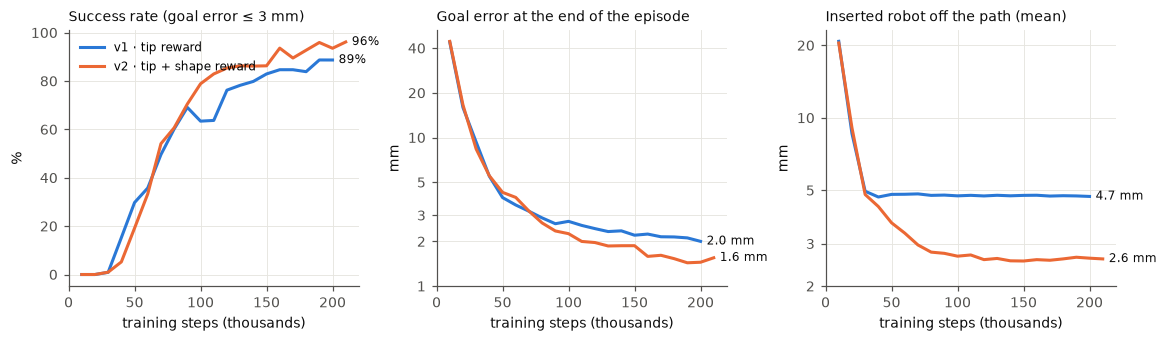

In [4]:
def load_run(run):
    # Monitor CSVs -> per-episode records with an estimate of the global step
    # (episode end in its own env x number of envs, as rl/summarize.py does)
    files = sorted(glob.glob(f'{RES}/{run}/monitor_*.monitor.csv'))
    eps = []
    for fn in files:
        with open(fn) as f:
            next(f)
            rows = list(csv.DictReader(f))
        steps = 0
        for r in rows:
            steps += int(r['l'])
            eps.append(dict(step=steps * len(files), r=float(r['r']), success=r['success'] == 'True',
                            goal=float(r['goal_err_mm']), shape=float(r['shape_err_mm']),
                            outside=float(r['outside']) > 0, length=int(r['l'])))
    return sorted(eps, key=lambda e: e['step'])

def binned(eps, key, width=10_000, agg=np.mean):
    hi = max(e['step'] for e in eps)
    edges = np.arange(0, hi + width, width)
    x, y = [], []
    for a, b in zip(edges[:-1], edges[1:]):
        sel = [e[key] for e in eps if a < e['step'] <= b]
        if len(sel) >= 10:
            x.append(b / 1000); y.append(agg(sel))
    return np.array(x), np.array(y)

runs = {'v1 · tip reward': ('ppo_p44_server_v1', V1), 'v2 · tip + shape reward': ('ppo_p44_server_v2_shape', V2)}
data = {k: load_run(r) for k, (r, _) in runs.items()}
for k, e in data.items():
    print(f'{k}: {len(e)} episodes, {max(x["step"] for x in e) / 1000:.0f}k steps')

panels = [('success', 'Success rate (goal error ≤ 3 mm)', lambda v: 100 * np.mean(v), '%'),
          ('goal', 'Goal error at the end of the episode', np.mean, 'mm'),
          ('shape', 'Inserted robot off the path (mean)', np.mean, 'mm')]
fig, axs = plt.subplots(1, 3, figsize=(10.5, 3.0), constrained_layout=True)
for ax, (key, title, agg, unit) in zip(axs, panels):
    for k, (run, col) in runs.items():
        x, y = binned(data[k], key, agg=agg)
        ax.plot(x, y, color=col, label=k)
        ax.annotate(f'{y[-1]:.0f}{unit}' if unit == '%' else f'{y[-1]:.1f} {unit}', (x[-1], y[-1]),
                    xytext=(4, 0), textcoords='offset points', va='center', fontsize=8, color=INK)
    ax.set_title(title, fontsize=9, loc='left', color=INK)
    ax.set_xlabel('training steps (thousands)')
    ax.set_ylabel(unit)
    if key != 'success':
        ax.set_yscale('log')
        ticks = [1, 2, 3, 5, 10, 20, 40] if key == 'goal' else [2, 3, 5, 10, 20]
        ax.set_yticks(ticks); ax.set_yticklabels([str(t) for t in ticks]); ax.minorticks_off()
axs[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.savefig(f'{FIG}/learning_curves.png', bbox_inches='tight')
plt.show()

Both runs learn to avoid the wrong ventricle branch within ~40k steps (goal error drops from
~45 mm, the value of the nominal schedule alone, to < 10 mm). Afterwards v1 keeps improving the
tip but its body stays ~4.7 mm off the path for the whole run, because nothing in its reward refers
to the body. Adding the shape term (v2) halves that deviation **and** speeds up tip accuracy:
keeping the body on the path keeps the tip in a configuration from which the goal is reachable.

### 6.2 Final evaluation

In [5]:
def rod_dev(z, e):
    r = z[f'rod_{e}']
    return np.min(np.linalg.norm(r[:, None] - z['path'][None], axis=2), axis=1).mean()

def summarise(fn):
    z = np.load(fn)
    n = int(z['n'])
    g = np.array([float(z[f'goal_err_{e}']) for e in range(n)])
    dv = np.array([rod_dev(z, e) for e in range(n)])
    return n, g, dv

rows = []
for label, run, last_bin in [('v1 · tip reward', 'v1', 'ppo_p44_server_v1'), ('v2 · tip + shape', 'v2', 'ppo_p44_server_v2_shape')]:
    eps = load_run(last_bin)
    tail = [e for e in eps if e['step'] > max(x['step'] for x in eps) - 20_000]
    det = 'v1_190k_det' if run == 'v1' else 'v2_final_det'
    _, gd, dd = summarise(f'{RES}/rollouts/{det}.npz')
    ev = f'{RES}/rollouts/eval30_{run}.npz'
    if not os.path.exists(ev):
        ev = f'{RES}/rollouts/{"v1_190k" if run == "v1" else "v2_final"}_sampled.npz'
    n, g, dv = summarise(ev)
    rows.append([label, f'{100 * np.mean([e["success"] for e in tail]):.0f}%', f'{np.mean([e["goal"] for e in tail]):.2f}',
                 f'{np.mean([e["shape"] for e in tail]):.2f}', f'{gd[0]:.2f}', f'{dd[0]:.2f}',
                 f'{100 * np.mean(g <= 3):.0f}% ({n})', f'{np.median(g):.2f} [{np.percentile(g, 90):.2f}]', f'{dv.mean():.2f}'])
hdr = ['policy', 'train: success', 'train: goal err', 'train: shape err', 'det: goal err', 'det: rod off path',
       'eval: success (n)', 'eval: goal err median [p90]', 'eval: rod off path']
w = [max(len(str(r[i])) for r in rows + [hdr]) for i in range(len(hdr))]
for r in [hdr] + rows:
    print('  '.join(str(c).ljust(w[i]) for i, c in enumerate(r)))
print('\ntrain = last 20k training steps (stochastic policy); det = deterministic policy (mean action);'
      '\neval = 30 new episodes with sampled actions (seed 7), same anatomy; errors in mm.')
json.dump({'header': hdr, 'rows': rows}, open(f'{FIG}/eval_table.json', 'w'))

policy            train: success  train: goal err  train: shape err  det: goal err  det: rod off path  eval: success (n)  eval: goal err median [p90]  eval: rod off path
v1 · tip reward   89%             2.05             4.73              1.21           4.61               90% (30)           1.79 [2.97]                  4.64              
v2 · tip + shape  95%             1.45             2.61              0.67           2.47               97% (30)           1.36 [2.62]                  2.58              

train = last 20k training steps (stochastic policy); det = deterministic policy (mean action);
eval = 30 new episodes with sampled actions (seed 7), same anatomy; errors in mm.


### 6.3 Trajectories

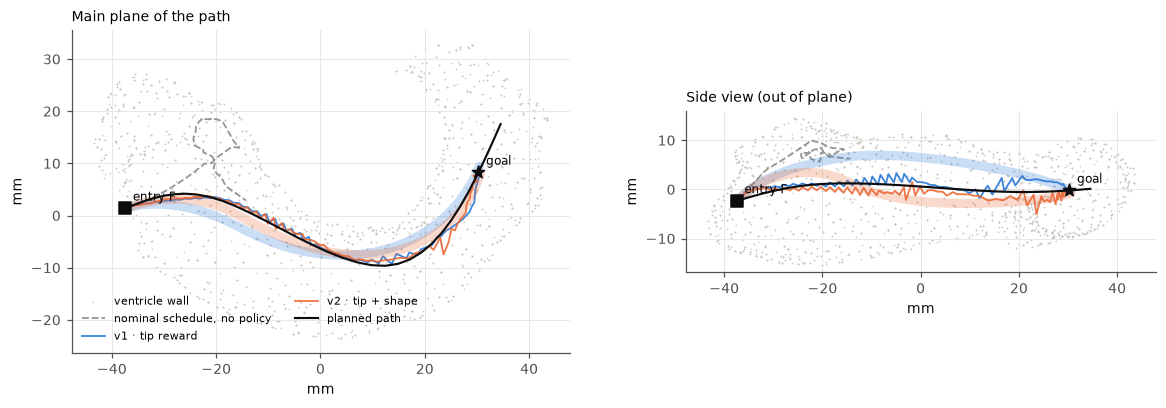

thin lines: tip trajectory per RL step (deterministic policy); wide translucent bands: final robot body


In [6]:
c = path.mean(0); _, _, Vt = np.linalg.svd(path - c); P = lambda x: (x - c) @ Vt.T
near = wall[np.min(np.linalg.norm(wall[:, None] - path[None, ::3], axis=2), 1) < 25]
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6), constrained_layout=True,
                        gridspec_kw={'width_ratios': [1.25, 1]})
for ax, (i, j, title) in zip(axs, [(0, 1, 'Main plane of the path'), (0, 2, 'Side view (out of plane)')]):
    q = P(near); ax.scatter(q[:, i], q[:, j], s=1.2, color=WALL, lw=0, label='ventricle wall')
    for name, col, lab in [('unity_baseline', BASE, 'nominal schedule, no policy'),
                           ('unity_v1', V1, 'v1 · tip reward'), ('unity_v2', V2, 'v2 · tip + shape')]:
        zz = np.load(f'{RES}/rollouts/{name}.npz')
        tip = P(zz['rods_0'][:, -1]); rod = P(zz['rods_0'][-1])
        ax.plot(tip[:, i], tip[:, j], color=col, lw=1.2, alpha=0.9, ls='--' if name == 'unity_baseline' else '-', label=lab)
        if name != 'unity_baseline':
            ax.plot(rod[:, i], rod[:, j], color=col, lw=6, alpha=0.25, solid_capstyle='round')
    q = P(path); ax.plot(q[:, i], q[:, j], color=INK, lw=1.4, label='planned path')
    for p, m, lab in [(F, 's', 'entry F'), (goal, '*', 'goal')]:
        q = P(p[None])[0]; ax.scatter(q[i], q[j], marker=m, s=70, color=INK, zorder=5)
        ax.annotate(lab, (q[i], q[j]), xytext=(5, 5), textcoords='offset points', fontsize=8)
    ax.set_aspect('equal'); ax.set_title(title, fontsize=9, loc='left'); ax.set_xlabel('mm'); ax.set_ylabel('mm')
axs[0].legend(frameon=False, fontsize=7.5, loc='lower left', ncol=2)
fig.savefig(f'{FIG}/trajectories.png', bbox_inches='tight')
plt.show()
print('thin lines: tip trajectory per RL step (deterministic policy); wide translucent bands: final robot body')

The nominal schedule alone (dashed) curls into another branch and ends 45 mm from the goal. Both
policies follow the path; in the side view the v1 body (wide blue band) bows ~6 mm above the
path while v2's body stays within ~3 mm of it.

### 6.4 Learning dynamics in the policy itself

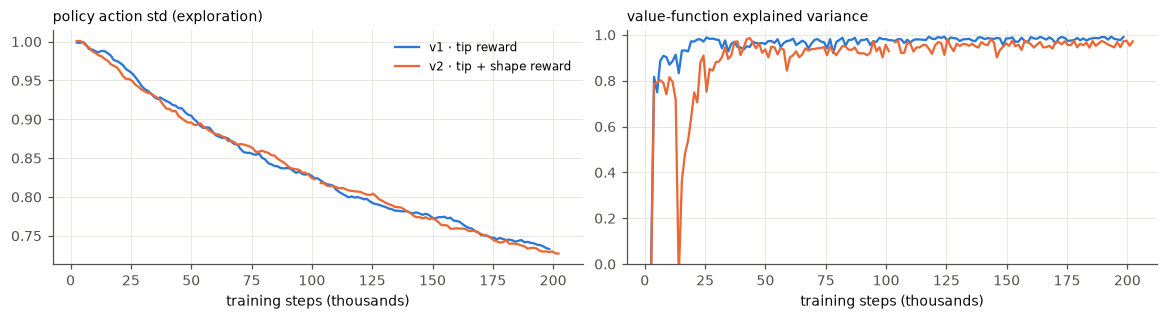

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 2.8), constrained_layout=True)
for k, (run, col) in runs.items():
    files = sorted(glob.glob(f'{RES}/{run}/progress*.csv'), key=lambda f: ('upto' not in f, f))
    rows = [r for f in files for r in csv.DictReader(open(f))]
    st = np.array([float(r['time/total_timesteps']) for r in rows]) / 1000
    for ax, key, lab in [(axs[0], 'train/std', 'policy action std (exploration)'),
                         (axs[1], 'train/explained_variance', 'value-function explained variance')]:
        y = np.array([float(r[key]) if r.get(key) else np.nan for r in rows])
        ax.plot(st, y, color=col, lw=1.5, label=k); ax.set_title(lab, fontsize=9, loc='left')
        ax.set_xlabel('training steps (thousands)')
axs[1].set_ylim(0, 1.02); axs[0].legend(frameon=False, fontsize=8)
fig.savefig(f'{FIG}/ppo_diagnostics.png', bbox_inches='tight')
plt.show()

## 7. Discussion, limitations, next steps

**What worked.** Residual RL on top of a physically fitted nominal schedule makes the problem
learnable in ~10⁵ simulator steps: the policy only has to learn corrections, and the nominal
schedule already encodes the gross shape. Reward shaping with a body-to-path term is the most
effective change made: it improves the clinically relevant quantity (how far the instrument body
strays, a proxy for wall loading) and the task metric at the same time.

**Engineering lessons.** (1) Simulator settings are part of the task: an under-converged contact
solver changes which ventricle branch the robot enters. (2) Long simulation-in-the-loop training
needs resource management — worker respawning removed the out-of-memory failure without losing
steps. (3) One environment per process is required because the SOFA scene is configured at import.

**Limitations.** One anatomy (patient 44, right) for training and testing; rigid wall (the
planned poroviscoelastic wall with contact history is not yet in); no sensing noise, no domain
randomisation; deterministic simulator; evaluation n = 30 sampled episodes per policy.

**Next steps.** Train across the 80 patient paths with held-out patients; domain randomisation
(wall stiffness, friction, actuator gain, registration error); the history-dependent wall model
and the planned comparison of policies with and without contact-history information; non-learned
baselines (scripted schedule, inverse-kinematics tracking) for the final comparison.